# LangGraph 필수 구성요소**

LangGraph 는 LLM이 필수가 아니다.

the graph setup has nothing to do with Llms necessarily.
The node is just a function, in this case a silly function, but it's a function there and 
in a state and it's returning a state, and it doesn't need to have anything to do with llms.


## 1. LangGraph란?

**LangGraph**는 상태 기반의 멀티 액터 애플리케이션을 구축하기 위한 프레임워크입니다.

https://docs.langchain.com/oss/python/langgraph/overview

### 핵심 구성 요소

1. **State (상태)** - 그래프가 관리하는 데이터
2. **Node (노드)** - 상태를 변경하는 함수
3. **Edge (엣지)** - 노드 간의 연결
4. **Graph (그래프)** - 전체 워크플로우



# [State] Schema 3가지 방법

https://docs.langchain.com/oss/python/langgraph/graph-api#schema

##  TypedDict 기본 사용법

Python의 `TypedDict`는 딕셔너리의 키와 값의 타입을 명시할 수 있습니다.

TypedDict는 타입 힌트만 제공하며, 런타임 검증은 수행하지 않습니다.

https://docs.langchain.com/oss/python/langgraph/graph-api#schema


In [1]:
from typing_extensions import TypedDict
# typing_extensions 모듈에서 TypedDict를 가져옴
# TypedDict는 "딕셔너리인데, 어떤 키에 어떤 타입의 값이 들어가야 하는지" 정의할 수 있게 해줌
# 즉, 일반 dict는 키와 값의 타입이 자유롭지만, TypedDict는 구조를 강제(타입 체크 용도)할 수 있음

class User(TypedDict):
    # User라는 이름의 TypedDict 정의
    # 실제로는 런타임에 dict와 동일하게 동작하지만, 정적 타입 검사기(mypy, IDE 등)가
    # 아래 필드들의 타입을 체크할 수 있게 해줌
    id: int       # id 키에는 정수(int) 타입의 값이 들어와야 함
    name: str     # name 키에는 문자열(str) 타입의 값이 들어와야 함
    email: str    # email 키에는 문자열(str) 타입의 값이 들어와야 함

# 올바른 타입의 데이터
user1: User = {
    # user1 변수는 User 타입(TypedDict 구조)을 따른다고 명시
    # 아래 딕셔너리는 User에서 정의한 필드(id, name, email)와 타입을 모두 만족함
    'id': 1,                      # int 타입 → OK
    'name': 'jino',                # str 타입 → OK
    'email': 'example@gmail.com'   # str 타입 → OK
}

print("User 1:", user1)
# 실행 결과: User 1: {'id': 1, 'name': 'jino', 'email': 'example@gmail.com'}
# 주의: TypedDict는 런타임에는 그냥 평범한 dict이기 때문에
# 타입이 틀려도 실행 자체는 에러 없이 됨 (예: id에 문자열을 넣어도 실행됨)
# 타입 오류는 mypy 같은 정적 타입 검사 도구를 돌려야 잡을 수 있음

User 1: {'id': 1, 'name': 'jino', 'email': 'example@gmail.com'}


In [2]:
# 잘못된 타입을 사용해도 런타임에는 에러가 발생하지 않습니다
# (TypedDict는 타입 힌트일 뿐, 런타임 검증을 하지 않음)

user2: User = {
    # user2도 User 타입으로 선언했지만, 'name'에 의도적으로 잘못된 타입(int)을 넣음
    'id': 1,        # int 타입 → User 정의와 일치 (OK)
    'name': 123,    # ⚠️ 원래는 str이어야 하는데 int(숫자)를 넣음 → 타입 정의 위반
                    # 하지만 파이썬 인터프리터는 이걸 검사하지 않으므로 에러 없이 그대로 실행됨
    'email': 'example@gmail.com'  # str 타입 → OK
}

print("User 2:", user2)
# 실행 결과: User 2: {'id': 1, 'name': 123, 'email': 'example@gmail.com'}
# name이 123(int)으로 들어가 있어도 프로그램은 정상적으로 출력됨


User 2: {'id': 1, 'name': 123, 'email': 'example@gmail.com'}


## Pydantic BaseModel 

`Pydantic`의 `BaseModel`은 런타임에 타입을 검증하고, 자동 변환도 수행합니다.

https://docs.langchain.com/oss/python/langgraph/graph-api#schema


In [7]:
from pydantic import BaseModel, ValidationError
# pydantic 모듈에서 BaseModel과 ValidationError를 가져옴
# BaseModel: 데이터 검증(validation)과 타입 강제를 실제로 "런타임에" 수행해주는 클래스
# ValidationError: 데이터가 정의된 타입/조건에 맞지 않을 때 발생하는 예외(에러) 클래스

class User(BaseModel):
    # User라는 이름의 Pydantic 모델(클래스) 정의
    # TypedDict와 모양은 비슷하지만, 동작 방식은 완전히 다름
    # -> 인스턴스를 생성하는 순간 실제로 타입 검사를 수행하고,
    #    타입이 안 맞으면 즉시 ValidationError를 발생시킴
    id: int       # id는 int 타입이어야 함 (검증됨)
    name: str     # name은 str 타입이어야 함 (검증됨)
    email: str    # email은 str 타입이어야 함 (검증됨)

# 올바른 데이터
user_data = {
    # 일반 딕셔너리(dict)로 먼저 데이터를 준비
    'id': 1,
    'name': 'jino',
    'email': 'example@gmail.com'
}

user1 = User(**user_data)
# User(**user_data) → 딕셔너리를 키워드 인자로 풀어서(unpacking) User 클래스에 전달
# 즉, User(id=1, name='jino', email='example@gmail.com')와 동일한 의미
# 이 시점에 Pydantic이 내부적으로 각 필드의 타입을 검사함
# 모든 값이 타입과 일치하므로 정상적으로 User 인스턴스(객체)가 생성됨

print("User 1:", user1)
# Pydantic 모델은 자체적으로 보기 좋은 문자열 표현(__repr__)을 제공함
# 실행 결과: User 1: id=1 name='jino' email='example@gmail.com'
# (TypedDict처럼 {} 형태가 아니라, 객체 형태로 출력되는 것이 특징)

print("타입:", type(user1))
# user1의 실제 타입을 출력
# 실행 결과: 타입: <class '__main__.User'>
# -> user1은 단순 dict가 아니라 진짜 'User' 클래스의 인스턴스(객체)임
#    (TypedDict의 user1은 사실 dict 타입이었던 것과 대조적)

User 1: id=1 name='jino' email='example@gmail.com'
타입: <class '__main__.User'>


In [8]:
# 자동 타입 변환
user_data2 = {
    'id': '2',  # 문자열이지만 int로 자동 변환됨
    # 'id'는 User 모델에서 int로 정의했지만, 여기서는 문자열 '2'(str)를 넣음
    # 그런데 '2'는 "숫자로 변환 가능한 문자열"이기 때문에
    # Pydantic이 에러를 내는 대신 알아서 int(2)로 바꿔서 받아들임
    # (이걸 "타입 강제 변환" 또는 "type coercion"이라고 부름)
    'name': 'nayeon_park',   # str 타입 그대로 입력 → 문제 없음
    'email': 'example@gmail.com'  # str 타입 그대로 입력 → 문제 없음
}

user2 = User(**user_data2)
# User(**user_data2) 실행 시 Pydantic이 내부적으로 다음과 같이 동작함:
# 1. id 필드를 보니 정의된 타입은 int인데, 들어온 값은 '2'(str)
# 2. '2'를 int로 변환 시도 → int('2') = 2 → 변환 성공
# 3. 변환된 값(2)으로 User 인스턴스를 생성
# 만약 'id': 'abc' 처럼 숫자로 변환이 불가능한 문자열이었다면
# 이때는 변환에 실패하므로 ValidationError가 발생함

print("User 2:", user2)
# 실행 결과: User 2: id=2 name='nayeon_park' email='example@gmail.com'
# 주목할 점: 출력된 id는 '2'(문자열)가 아니라 2(정수)로 표시됨
# 즉, 원래 입력은 문자열이었지만, 실제 저장된 값은 int로 "변환되어" 저장됨

print(type(user2.id))
# 추가로 확인해보면 좋은 부분 (선택)
# 실행 결과: <class 'int'>
# user2.id가 진짜로 int 타입으로 변환되었음을 확인할 수 있음

User 2: id=2 name='nayeon_park' email='example@gmail.com'
<class 'int'>


In [9]:
# 변환 불가능한 타입이면 오류 발생
try:
    user_data3 = {
        'id': 'abc',  # 변환 불가능
        'name': 'nayeon_park',
        'email': 'example@gmail.com'
    }
    user3 = User(**user_data3)
except ValidationError as e:
    print("❌ ValidationError 발생:")
    print(e)

❌ ValidationError 발생:
1 validation error for User
id
  Input should be a valid integer, unable to parse string as an integer [type=int_parsing, input_value='abc', input_type=str]
    For further information visit https://errors.pydantic.dev/2.11/v/int_parsing


## dataclass

상태에 기본값을 제공하려면 데이터 클래스를 사용하세요.

https://docs.langchain.com/oss/python/langgraph/graph-api#schema

In [11]:
from dataclasses import dataclass
# dataclasses 모듈에서 dataclass 데코레이터를 가져옴
# dataclass는 클래스에 __init__, __repr__, __eq__ 등을 자동으로 만들어주는 기능
# 단, Pydantic처럼 런타임 타입 검증은 해주지 않음 (이 점이 이번 예제의 핵심)


# ──────────────────────────────────────────────
# 1. 스키마 정의
# ──────────────────────────────────────────────
@dataclass
class User:
    # @dataclass를 붙이면 아래 필드들을 기반으로
    # __init__(self, id, name, email) 메서드가 자동 생성됨
    id: int       # id는 int 타입이어야 한다는 "힌트"
    name: str     # name은 str 타입이어야 한다는 "힌트"
    email: str    # email은 str 타입이어야 한다는 "힌트"


In [12]:
# ──────────────────────────────────────────────
# 2. 케이스 1: 올바른 타입의 데이터 대입
# ──────────────────────────────────────────────
print("=== 케이스 1: 정상 데이터 ===")

user1 = User(id=1, name="jino", email="example@gmail.com")
# User(...)는 자동 생성된 __init__을 호출하는 것
# 단순히 각 필드에 값을 그대로 저장할 뿐, 타입이 맞는지는 검사하지 않음

print("User 1:", user1)
# __repr__이 자동 생성되어 있어서 사람이 보기 좋은 형태로 출력됨
# 실행 결과: User 1: User(id=1, name='jino', email='example@gmail.com')

print("타입:", type(user1))
# 실행 결과: 타입: <class '__main__.User'>
# -> dataclass도 Pydantic처럼 "진짜 클래스 인스턴스"를 만들어줌 (dict가 아님)
# 이 점은 TypedDict와 다르고, Pydantic BaseModel과 비슷함

=== 케이스 1: 정상 데이터 ===
User 1: User(id=1, name='jino', email='example@gmail.com')
타입: <class '__main__.User'>


In [13]:
# ──────────────────────────────────────────────
# 3. 케이스 2: 잘못된 타입의 데이터 대입
#    -> dataclass는 검증을 하지 않으므로 에러 없이 그대로 저장됨
# ──────────────────────────────────────────────
print("\n=== 케이스 2: 잘못된 타입 데이터 ===")

user2 = User(id="1", name=123, email="example@gmail.com")
# id에는 int 대신 문자열 "1"을 넣음 -> 타입 힌트 위반이지만 에러 없음
# name에는 str 대신 정수 123을 넣음 -> 타입 힌트 위반이지만 에러 없음
# dataclass는 Pydantic과 달리 "값을 검사하거나 변환하는 로직"이 전혀 없음
# 단순히 필드에 값을 대입하는 역할만 함 (일반 클래스의 __init__과 동일한 수준)

print("User 2:", user2)
# 실행 결과: User 2: User(id='1', name=123, email='example@gmail.com')

print("id 타입:", type(user2.id))     # 실행 결과: <class 'str'>  (변환 안 됨, 그대로 str)
print("name 타입:", type(user2.name)) # 실행 결과: <class 'int'>  (변환 안 됨, 그대로 int)
# -> Pydantic이었다면 id="1"은 int(1)로 자동 변환되고, name=123은 ValidationError가 났을 것
# -> dataclass는 둘 다 아무 조치 없이 "있는 그대로" 저장함


=== 케이스 2: 잘못된 타입 데이터 ===
User 2: User(id='1', name=123, email='example@gmail.com')
id 타입: <class 'str'>
name 타입: <class 'int'>


In [14]:
from dataclasses import dataclass, field
# dataclass: 클래스에 __init__ 등을 자동 생성해주는 데코레이터
# field: dataclass의 필드에 "기본값 생성 방식"을 세밀하게 지정할 때 사용하는 함수
#        (특히 list, dict처럼 변경 가능한(mutable) 타입의 기본값을 다룰 때 꼭 필요함)


# ──────────────────────────────────────────────
# 1. 기본값(default)이 있는 State 스키마 정의
# ──────────────────────────────────────────────
@dataclass
class State:
    # ⚠️ dataclass 규칙: 기본값이 없는 필드는 항상 기본값이 있는 필드보다 "먼저" 와야 함
    # (순서가 바뀌면 "non-default argument follows default argument" 에러 발생)

    user_input: str
    # 기본값이 없는 필드 -> State 생성 시 반드시 값을 넘겨줘야 함 (필수 입력값)

    processed_text: str = ""
    # 기본값이 있는 필드 -> 값을 안 넘기면 자동으로 빈 문자열("")이 들어감
    # str, int, bool처럼 "변경 불가능한(immutable)" 타입은 이렇게 = 값 형태로 기본값을 줘도 안전함

    history: list = field(default_factory=list)
    # ⚠️ list, dict, set처럼 "변경 가능한(mutable)" 타입은 절대로 history: list = [] 처럼 쓰면 안 됨!
    # 그렇게 쓰면 모든 인스턴스가 "동일한 하나의 리스트 객체"를 공유하게 되는 버그가 생김
    # (한 인스턴스에서 append하면 다른 인스턴스의 값도 같이 바뀌어버림)
    # field(default_factory=list)를 쓰면, 인스턴스를 만들 때마다 list()를 "새로" 호출해서
    # 서로 독립적인 빈 리스트를 만들어줌 -> 안전한 방식

    retry_count: int = 0
    # 기본값이 있는 필드 -> 값을 안 넘기면 0이 들어감 (예: 재시도 횟수 카운터로 활용)


# ──────────────────────────────────────────────
# 2. 케이스 1: 필수 필드만 넘기고 나머지는 기본값 사용
# ──────────────────────────────────────────────
print("=== 케이스 1: 기본값만 사용 ===")

s1 = State(user_input="안녕")
# user_input만 넘겼고, processed_text / history / retry_count는 모두 기본값으로 채워짐
print(s1)
# 실행 결과: State(user_input='안녕', processed_text='', history=[], retry_count=0)


# ──────────────────────────────────────────────
# 3. 케이스 2: 일부 필드만 기본값을 덮어쓰기
# ──────────────────────────────────────────────
print("\n=== 케이스 2: 일부 필드 덮어쓰기 ===")

s2 = State(user_input="안녕", retry_count=3)
# user_input과 retry_count만 직접 지정, processed_text와 history는 여전히 기본값
print(s2)
# 실행 결과: State(user_input='안녕', processed_text='', history=[], retry_count=3)


# ──────────────────────────────────────────────
# 4. 케이스 3: default_factory의 효과 확인
#    -> 각 인스턴스가 "독립된" 리스트를 갖는지 검증
# ──────────────────────────────────────────────
print("\n=== 케이스 3: history는 인스턴스마다 독립적인가? ===")

s3 = State(user_input="hi")
s3.history.append("첫 메시지")
# s3의 history 리스트에만 값을 추가함

print("s3.history:", s3.history)        # 실행 결과: ['첫 메시지']
print("s1.history:", s1.history)        # 실행 결과: []  (s3에서 추가한 내용이 영향 없음)
print("같은 객체인가?", s1.history is s3.history)
# 실행 결과: False
# -> field(default_factory=list) 덕분에 s1과 s3가 서로 다른 리스트 객체를 갖고 있음을 확인
# (만약 history: list = [] 로 잘못 썼다면 이 결과는 True가 되고, 심각한 버그로 이어짐)

=== 케이스 1: 기본값만 사용 ===
State(user_input='안녕', processed_text='', history=[], retry_count=0)

=== 케이스 2: 일부 필드 덮어쓰기 ===
State(user_input='안녕', processed_text='', history=[], retry_count=3)

=== 케이스 3: history는 인스턴스마다 독립적인가? ===
s3.history: ['첫 메시지']
s1.history: []
같은 객체인가? False


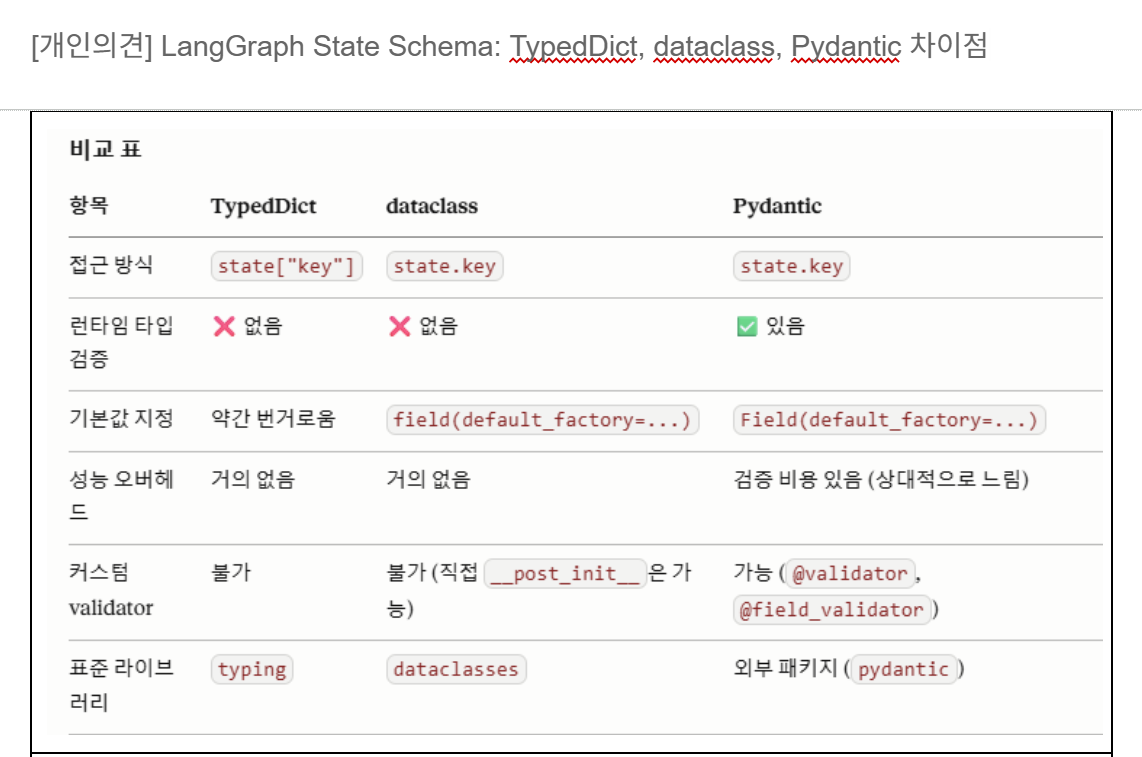 


---


# LangGraph 생성

Step 1: Define the State object

    You can use any python object; but it's most common to use a TypedDict or a Pydantic BaseModel.

Step 2: Start the Graph Builder with this State class

Step 3: Create a Node

    A node can be any python function.
    The reducer that we set before gets automatically called to combine this response with previous responses

Step 4: Create Edges

Step 5: Compile the Graph

## [EX1] LangGraph 기초  — 간단한 덧셈/뺄셈 워크플로

In [44]:
# ✅ LangGraph 기초 예시 — 간단한 덧셈/뺄셈 워크플로
from typing import TypedDict


# ✅ 1️⃣ State 정의 — 그래프 전체에서 공유되는 데이터
class CalcState(TypedDict):
    value: int  # 현재 숫자 상태

In [45]:
# ✅ 2️⃣ Node 정의 — 각각의 계산 단계를 함수로 표현
def add_five(state: CalcState) -> CalcState:
    print("[1단계] 5 더하기")
    state["value"] += 5
    return state

def subtract_two(state: CalcState) -> CalcState:
    print("[2단계] 2 빼기")
    state["value"] -= 2
    return state

def show_result(state: CalcState) -> CalcState:
    print("[3단계] 결과 출력")
    print(f"🎯 최종 결과: {state['value']}")
    return state

In [46]:
from langgraph.graph import StateGraph, START, END

# ✅ 3️⃣ 그래프 생성
builder = StateGraph(CalcState)

# 노드 등록
builder.add_node("add", add_five)
builder.add_node("subtract", subtract_two)
builder.add_node("result", show_result)

In [47]:
# ✅ 4️⃣ 실행 순서(Edge) 정의
builder.add_edge(START, "add")
builder.add_edge("add", "subtract")
builder.add_edge("subtract", "result")
builder.add_edge("result", END)

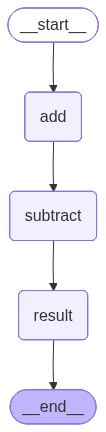

In [50]:
# ✅ 5️⃣ 그래프 컴파일 
app = builder.compile()
app

In [51]:
# ✅ 6️⃣ 그래프 실행
result = app.invoke({"value": 2})  # 초기값 0에서 시작

print("\n=== 계산 완료 ===")
print(f"최종 State: {result}")

[1단계] 5 더하기
[2단계] 2 빼기
[3단계] 결과 출력
🎯 최종 결과: 5

=== 계산 완료 ===
최종 State: {'value': 5}


## [EX2] 공식 사이트

https://docs.langchain.com/oss/python/langgraph/graph-api


In [93]:
from typing import TypedDict
from langgraph.graph import END, START, StateGraph


# ──────────────────────────────────────────────
# 1. 네 가지 스키마를 역할별로 분리 정의
# ──────────────────────────────────────────────

class InputState(TypedDict):
    # 사용자가 graph.invoke(...) 호출 시 "넘겨야 하는" 입력 구조
    user_input: str


class OutputState(TypedDict):
    # 그래프 실행이 끝난 뒤 "최종적으로 보여줄" 출력 구조
    graph_output: str


class OverallState(TypedDict):
    # 그래프 "내부에서" 노드들이 공통으로 공유하는 전체 state 구조
    # InputState, OutputState의 필드를 모두 포함하면서, 중간 처리용 필드(foo)도 추가로 가짐
    foo: str           # node_1과 node_2 사이에서 전달되는 중간 결과
    user_input: str    # 입력값 (InputState에서 흘러들어옴)
    graph_output: str  # 최종 출력값 (OutputState로 흘러나갈 값)


class PrivateState(TypedDict):
    # 특정 노드들 "사이에서만" 쓰이는 비공개(private) state
    # OverallState에는 포함되지 않는 별도의 구조 -> 그래프 전체에 노출되지 않고
    # node_2 -> node_3 사이에서만 전달되는 임시 데이터
    bar: str


# ──────────────────────────────────────────────
# 2. 각 노드: 입력 타입과 출력 타입이 서로 다른 스키마를 사용
#    (LangGraph는 함수의 타입 힌트와 무관하게, 실제로는 그래프 컴파일 시점에
#     필요한 키만 꺼내고, 반환된 dict의 키만 기존 state에 병합하는 방식으로 동작함)
# ──────────────────────────────────────────────

def node_1(state: InputState) -> OverallState:
    # Write to OverallState
    # 타입 힌트상으로는 InputState를 받지만, 실제로는 OverallState(전체 state)가 전달됨
    # InputState에 정의된 user_input 필드만 사용하겠다는 의도로 타입을 좁혀서 표기

    return {"foo": state["user_input"] + " name"}
    # state["user_input"]에 " name"을 붙여서 foo 필드에 저장
    # 반환된 {"foo": ...}는 OverallState의 foo 필드에 병합(업데이트)됨
    # 예: user_input="My name" -> foo="My name name"


def node_2(state: OverallState) -> PrivateState:
    # Read from OverallState, write to PrivateState
    # OverallState를 입력으로 받아서 foo 값을 읽고,
    # 결과는 PrivateState(bar 필드)에 쓰겠다는 의도

    return {"bar": state["foo"] + " is"}
    # foo 값에 " is"를 붙여서 bar 필드로 반환
    # 예: foo="My name name" -> bar="My name name is"
    # 이 bar 값은 OverallState에는 존재하지 않는 필드이지만,
    # LangGraph가 내부적으로 다음 노드(node_3)에 전달할 수 있도록 처리해줌


def node_3(state: PrivateState) -> OutputState:
    # Read from PrivateState, write to OutputState
    # 직전 노드(node_2)가 만든 PrivateState(bar)를 읽어서
    # 최종적으로 OutputState(graph_output)를 만들어 반환

    return {"graph_output": state["bar"] + " Lance"}
    # bar 값에 " Lance"를 붙여서 최종 결과(graph_output) 생성
    # 예: bar="My name name is" -> graph_output="My name name is Lance"


# ──────────────────────────────────────────────
# 3. 그래프 구성
# ──────────────────────────────────────────────

builder = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
# 그래프의 "전체 state"는 OverallState를 기준으로 관리
# 입력은 InputState만 받고, 출력은 OutputState만 노출하도록 제한

builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)
# 3개의 노드를 각각 이름과 함께 등록

builder.add_edge(START, "node_1")     # 시작 -> node_1
builder.add_edge("node_1", "node_2")  # node_1 -> node_2
builder.add_edge("node_2", "node_3")  # node_2 -> node_3
builder.add_edge("node_3", END)       # node_3 -> 종료
# 노드들을 순서대로 일렬로 연결 (단순 선형 파이프라인 구조)

graph = builder.compile()
# 지금까지의 구성을 실행 가능한 그래프 객체로 컴파일

In [94]:
graph.invoke({"user_input": "My"})
# {'graph_output': 'My name is Lance'}

{'graph_output': 'My name is Lance'}

## [EX2] LangGraph 기초  단어 조합해서 메세지 출력

In [18]:
# Some useful constants
# 예제로 사용할 단어들 LangGraph를 컴파일하면  실행하면 2개의 단어를 조합해서 문장을 만듦
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Zombies", "Rainbows", "Eels", "Pickles", "Muffins"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "moody", "sparkly", "untrustworthy", "sarcastic", "squishy", "haunted"]

In [19]:
### Step 1: Define the State object
# You can use any python object; but it's most common to use a TypedDict or a Pydantic BaseModel.
from typing import Annotated
from langgraph.graph.message import add_messages
class State(BaseModel):        
    messages: Annotated[list, add_messages]


In [20]:
### Step 2: Start the Graph Builder with this State class
from langgraph.graph import StateGraph
graph_builder = StateGraph(State)

In [21]:
### Step 3: Create a Node
import random
def our_first_node(old_state: State) -> State:
    reply = f"{random.choice(nouns)} are {random.choice(adjectives)}"
    messages = [{"role": "assistant", "content": reply}]
    new_state = State(messages=messages)
    return new_state

graph_builder.add_node("first_node", our_first_node)

In [23]:
### Step 4: Create Edges
from langgraph.graph import StateGraph, START, END
graph_builder.add_edge(START, "first_node")
graph_builder.add_edge("first_node", END)

In [24]:
### Step 5: Compile the Graph
graph = graph_builder.compile()

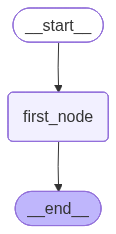

In [26]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
result = graph.invoke({"messages": "What is the capital of France?"});
print("\n=== 실행 완료 ===")
print(f"최종 State: {result}")
print(f"최종 메시지: {result['messages'][1].content }")


=== 실행 완료 ===
최종 State: {'messages': [HumanMessage(content='What is the capital of France?', additional_kwargs={}, response_metadata={}, id='7beeecd3-f4b0-4e39-ae07-c9d5cdce8e88'), AIMessage(content='Unicorns are pedantic', additional_kwargs={}, response_metadata={}, id='46e6b56e-b13c-4ebc-80b0-cac1a47d5497', tool_calls=[], invalid_tool_calls=[])]}
최종 메시지: Unicorns are pedantic


---

---

# LLM & LangGraph 

## [EX1] OpenAI & LLM 기반 2단계 그래프

In [88]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("API Key가 설정되었습니다.")

API Key가 설정되었습니다.


In [89]:
from typing_extensions import TypedDict
# TypedDict: 딕셔너리 구조에 타입 힌트를 부여하는 도구 (런타임 검증은 없음)


# 입력을 위한 스키마 정의
class InputState(TypedDict):
    # 그래프를 "호출(invoke)"할 때 사용자가 넘겨야 하는 입력 데이터의 구조
    # 즉, graph.invoke({"question": "..."}) 처럼 호출할 때 필요한 필드만 정의함
    question: str   # 사용자가 던진 질문


# 출력을 위한 스키마 정의
class OutputState(TypedDict):
    # 그래프 실행이 끝났을 때, 최종적으로 사용자에게 "보여줄" 결과의 구조
    # 즉, graph.invoke(...)의 반환값에서 사용자가 받아야 하는 필드만 정의함
    answer: str   # 최종 생성된 답변


# 입력과 출력을 합한 종합 스키마 정의
class OverallState(InputState, OutputState):
    # OverallState는 InputState와 OutputState를 "다중 상속"받아서 만든 통합 스키마
    # 즉, OverallState는 question과 answer를 모두 가진 구조가 됨
    # (TypedDict도 일반 클래스처럼 상속이 가능하며, 부모의 필드를 모두 물려받음)
    #
    # 이 OverallState는 그래프 "내부"에서 실제로 노드들이 주고받는 전체 state로 사용됨
    # -> 그래프 내부 노드들은 question, answer뿐 아니라
    #    필요하다면 여기에 retrieved_docs, intermediate_steps 같은 "중간 처리용 필드"도
    #    추가로 더 가질 수 있음 (지금 예시에서는 단순화를 위해 입력+출력만 합침)
    pass
    # 본문이 따로 없으므로 pass로 처리
    # (부모 클래스들의 필드만 그대로 물려받고, 새로 추가하는 필드는 없다는 의미)

In [90]:
# 입력을 처리하고 답변을 생성하는 노드 정의
from langchain.chat_models import init_chat_model
# init_chat_model: 모델 제공자(OpenAI, Anthropic 등)를 문자열만으로 자동 인식해서
# 적절한 ChatModel 인스턴스를 생성해주는 LangChain의 통합 헬퍼 함수
# (예: "gpt-5-mini"라고만 적어도 내부적으로 ChatOpenAI를 생성해 줌)

from langgraph.graph import StateGraph, START, END
# StateGraph: 노드/엣지로 그래프를 구성하는 핵심 클래스
# START, END: 그래프의 시작점/종료점을 나타내는 특수 상수


def answer_node(state: InputState):
    # 그래프의 노드로 사용될 함수
    # 타입 힌트로는 InputState를 받는다고 적혀있지만,
    # 실제로 LangGraph가 이 함수에 넘겨주는 값은 OverallState(전체 state)임
    # (InputState는 question 필드를 포함하고 있으므로, 타입 힌트만 InputState로 좁혀서 써도
    #  question에 접근하는 데는 문제가 없음 -> "내가 이 필드만 쓸 거야"라는 의도 표현용)

    question = state["question"]
    # state는 TypedDict 기반이라 dict처럼 ["question"] 형태로 접근함
    # 사용자가 그래프를 호출(invoke)할 때 넘긴 질문 값을 꺼냄

    model = init_chat_model("gpt-5-mini")
    # "gpt-5-mini" 모델을 사용하는 ChatModel 객체 생성
    # (실제 모델명은 사용 중인 LLM 제공자/버전에 맞게 바꿔서 사용해야 함)

    response = model.invoke(question)
    # 모델에 question(문자열)을 그대로 전달하여 응답을 요청
    # invoke()는 LangChain의 모든 Runnable 객체가 공통으로 갖는 실행 메서드
    # 반환값은 AIMessage 같은 메시지 객체

    answer = response.content
    # 응답 객체(response)에서 실제 텍스트 내용만 꺼냄 (response.content는 문자열)

    return {"answer": answer}
    # 노드는 "state에서 바뀐 부분만" dict로 반환하면 됨
    # 여기서는 answer 필드만 새로 채워서 반환 (question은 그대로 유지됨)
    # LangGraph가 이 반환값을 기존 state(OverallState)에 자동으로 병합(merge)해 줌


# 그래프 생성
graph_builder = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)
# StateGraph 생성 시 3가지 스키마를 지정:
# - 첫 번째 인자(OverallState): 그래프 "내부"에서 노드들이 실제로 주고받는 전체 state 타입
# - input_schema=InputState: 사용자가 graph.invoke(...)를 호출할 때 넘겨야 하는 입력 구조
#   -> question 필드만 받겠다는 뜻 (answer를 미리 넣어도 무시됨)
# - output_schema=OutputState: graph.invoke(...)의 최종 반환값에서 노출할 필드 구조
#   -> answer 필드만 사용자에게 보여주겠다는 뜻 (내부에 question이 남아있어도 최종 결과에는 숨겨짐)

graph_builder.add_node("answer_node", answer_node)
# "answer_node"라는 이름으로 위에서 만든 함수를 노드로 등록

graph_builder.add_edge(START, "answer_node")
# 그래프 시작(START) -> answer_node로 연결
# 즉, 그래프가 실행되면 가장 먼저 answer_node가 실행됨

graph_builder.add_edge("answer_node", END)
# answer_node -> 그래프 종료(END)로 연결
# answer_node 실행이 끝나면 그래프 실행도 종료됨

graph = graph_builder.compile()
# 지금까지 구성한 노드와 엣지를 실제로 실행 가능한 그래프 객체로 컴파일
# 이 graph 객체에 .invoke(), .stream() 등을 호출해서 실행할 수 있음

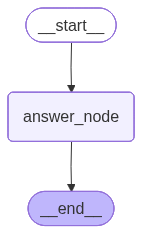

In [91]:
from IPython.display import Image, display
# IPython.display: Jupyter Notebook에서 다양한 형태의 결과물(이미지, HTML, 오디오 등)을
#                  셀 출력으로 보여주기 위한 모듈
# Image: 이미지 데이터(바이트)를 Jupyter에서 렌더링 가능한 형태로 감싸주는 클래스
# display: 객체를 Jupyter 셀 출력창에 실제로 "표시"해주는 함수
#          (print()와 달리 이미지, 표, HTML 등 다양한 리치 콘텐츠를 보여줄 수 있음)

display(Image(graph.get_graph().draw_mermaid_png()))
# 안쪽에서 바깥쪽 순서로 실행됨:
#
# 1) graph.get_graph()
#    -> 컴파일된 LangGraph 그래프(graph) 객체에서
#       노드와 엣지 정보를 담고 있는 "그래프 표현 객체"를 추출함
#       (앞서 add_node, add_edge로 정의했던 구조 정보가 여기에 담겨 있음)
#
# 2) .draw_mermaid_png()
#    -> 추출한 그래프 구조를 Mermaid 문법(다이어그램을 텍스트로 표현하는 형식)으로 변환한 뒤,
#       이를 다시 PNG 이미지(바이트 데이터)로 렌더링함
#       (내부적으로 Mermaid 다이어그램을 이미지로 그려주는 외부 API/서비스를 호출함)
#
# 3) Image(...)
#    -> 받아온 PNG 바이트 데이터를 IPython이 이해할 수 있는 Image 객체로 감쌈
#
# 4) display(...)
#    -> 최종적으로 해당 이미지를 Jupyter Notebook 셀 출력 영역에 그림으로 표시함
#
# 결과적으로: START -> answer_node -> END 같은 형태로
# 그래프의 노드/엣지 흐름이 한눈에 보이는 다이어그램 이미지가 출력됨

In [92]:
question = "넌 어떤 기능이 있어"
# 그래프에 던질 질문을 변수로 미리 정의
# (문자열을 변수에 담아두면 아래에서 재사용하기 편함)

result = graph.invoke({"question": question})
# graph.invoke(...)로 그래프를 실행
# 인자로 넘기는 dict는 input_schema=InputState 구조를 따라야 함
# -> InputState는 {"question": str}이므로, {"question": question}을 그대로 전달
# (만약 여기에 "answer" 같은 InputState에 없는 키를 넣어도 무시됨 -> input_schema가 입력을 제한해줌)
#
# 그래프 내부 동작 순서:
# 1) START -> answer_node로 진입
# 2) answer_node 함수가 호출되며, state["question"]으로 질문을 꺼내 LLM에 전달
# 3) LLM 응답을 받아 {"answer": "..."} 형태로 반환
# 4) answer_node -> END로 종료되며, 최종 state가 정리됨
# 5) output_schema=OutputState 덕분에, 최종 반환값(result)에는 answer 필드만 노출됨
#    (그래프 내부적으로 question도 OverallState에 들어있었지만, 출력 시에는 걸러짐)

print("입력:", {"question": question})
# 사용자가 그래프에 실제로 넘긴 입력값을 그대로 출력해서 확인
# 실행 결과 예시: 입력: {'question': '넌 어떤 기능이 있어'}

print("출력:", result)
# 그래프 실행 결과(result)를 출력
# output_schema=OutputState가 적용되어 있으므로,
# result는 {"answer": "..."} 형태만 가지고 있어야 함 (question 필드는 보이지 않음)
# 실행 결과 예시: 출력: {'answer': '저는 질문에 답변하는 기능이 있습니다...'}

입력: {'question': '넌 어떤 기능이 있어'}
출력: {'answer': '좋아요 — 간단히 정리할게요. 저는 여러 작업을 도와줄 수 있어요. 주요 기능은 다음과 같습니다.\n\n- 질문에 답하기: 일반 지식, 역사, 과학, 기술 등 설명과 배경 제공  \n- 정보 요약: 기사·문서·회의록 등을 간결하게 요약  \n- 번역: 한국어↔영어 등 여러 언어 번역 및 자연스러운 표현 제안  \n- 글쓰기·편집: 이메일, 보고서, 자기소개서, 블로그, 광고카피 등 작성·교정·문체 바꾸기  \n- 창작: 소설, 시, 대사, 아이디어 브레인스토밍, 게임/콘텐츠 기획  \n- 코딩 지원: 코드 작성·수정·디버깅, 알고리즘 설명, 예제 및 테스트 케이스 제공 (Python, JS 등)  \n- 수학·논리 문제 풀이: 단계별 풀이와 해설 제공  \n- 학습·튜터링: 개념 설명, 연습문제, 학습 계획 세우기  \n- 일정·계획 수립: 프로젝트 단계, 체크리스트, 공부·운동 플랜 등 구조화  \n- 인터뷰·대화 연습: 면접/프레젠테이션 연습, 피드백 제공  \n- 데이터 처리 도움: 간단한 데이터 분석 아이디어, SQL/엑셀 팁 (대규모 데이터 처리 불가)  \n- 역할극·시뮬레이션: 특정 인물·상황을 연기하며 연습 가능  \n- 상담적 대화: 정서적 지지·일상 대화 가능 (단, 전문적 의료·법률 상담 아님)\n\n제약(중요):\n- 실시간 인터넷 검색이나 외부 계정·파일에 직접 접근 불가(사용자가 내용 붙여넣으면 그 범위 내에서 작업 가능).  \n- 최신 정보가 필요하면(예: 최신 뉴스, 실시간 주가) 업데이트가 없을 수 있음.  \n- 의료·법률·재무 등 전문 영역은 일반 정보와 참고 의견만 제공, 최종 판단은 전문가와 상담 필요.  \n- 개인정보나 민감한 데이터는 공유하지 않는 게 안전함.\n\n원하시면 지금 바로 어떤 기능을 시도해볼까요? (예: 이메일 초안 작성, 코드 디버그, 글 요약 등)'}


## [EX2] OpenAI & LangGraph & 싱글턴

### Type Hints in Python

In [ ]:
from typing import Annotated
# typing 모듈에서 Annotated를 가져옴
# Annotated[타입, 메타데이터, ...]
# -> "이 값은 기본적으로 이 타입이지만, 추가로 이런 부가 정보(설명/메타데이터)도 같이 갖고 있다"
#    는 것을 표현하는 문법
# 메타데이터 자체는 파이썬 실행에 아무 영향을 주지 않음 (런타임에는 그냥 str과 동일하게 동작)
# 주로 사람이 읽기 위한 설명이나, 다른 도구(LangChain, FastAPI, mypy 등)가 활용하기 위한 용도

def shout(text: Annotated[str, "something to be shouted"]) -> str:
    # text: Annotated[str, "something to be shouted"]
    # -> text의 실제 타입은 str이고,
    #    "something to be shouted"(외쳐야 할 어떤 것)라는 설명이 메타데이터로 붙어있음
    # 이 설명은 IDE 툴팁이나 문서화, 혹은 LangChain의 도구(tool) 파라미터 설명 등으로 활용될 수 있음
    # 단, 파이썬 인터프리터 입장에서는 그냥 text: str과 동일하게 취급됨 (강제 검증 없음)

    print(text.upper())
    # text를 모두 대문자로 변환해서 출력
    # 예: "hello" -> "HELLO"

    return text.upper()
    # 변환된 대문자 문자열을 반환값으로 돌려줌


shout("hello")
# 함수 호출 -> 실행 결과: "HELLO"가 출력되고, 반환값도 "HELLO"
# Annotated에 붙은 메타데이터("something to be shouted")는
# 함수의 동작이나 출력 결과에 어떤 영향도 주지 않음 -> 순수히 부가 정보 역할만 함

HELLO


'HELLO'

 A word about "Annotated"

You probably know this; type hinting is a feature in Python that lets you specify the type of something:

`my_favorite_things: List`

But you may not know this:

You can also use something called "Annotated" to add extra information that somebody else might find useful:

`my_favorite_things: Annotated[List, "these are a few of mine"]`

LangGraph needs us to use this feature when we define our State object.

It wants us to tell it what function it should call to update the State with a new value.

This function is called a **reducer**.

LangGraph provides a default reducer called `add_messages` which takes care of the most common case.

And that hopefully explains why the State looks like this.




In [95]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("API Key가 설정되었습니다.")

API Key가 설정되었습니다.


In [96]:
from typing import Annotated
from pydantic import BaseModel
from langgraph.graph.message import add_messages
# Annotated: 타입에 부가 메타데이터(추가 정보)를 붙이는 문법
# BaseModel: Pydantic 모델 -> state 스키마를 정의하면서 런타임 타입 검증까지 받을 수 있음
# add_messages: LangGraph가 제공하는 "리듀서(reducer) 함수"
#   -> 이 필드에 새로운 값이 들어올 때, 기존 값을 "덮어쓰지" 않고
#      "기존 리스트 + 새 메시지"를 지능적으로 합쳐주는 역할을 함


# Step 1: Define the State object
class State(BaseModel):
    # 그래프 전체에서 공유되는 state 스키마를 Pydantic 모델로 정의
    # BaseModel을 썼기 때문에, messages에 list가 아닌 다른 타입이 들어오면
    # 런타임에 ValidationError가 발생함 (TypedDict였다면 검증 없이 그냥 통과됨)

    messages: Annotated[list, add_messages]
    # messages 필드의 실제 타입은 list
    # Annotated의 두 번째 인자(add_messages)는 "리듀서 함수" 역할을 지정하는 것
    #
    # 리듀서가 없는 일반 필드라면:
    #   노드가 {"messages": [새 메시지]}를 반환할 때, 기존 messages를 통째로 "교체"해버림
    #
    # add_messages 리듀서가 지정된 경우:
    #   노드가 {"messages": [새 메시지]}를 반환하면
    #   -> 기존 messages 리스트 뒤에 새 메시지를 "추가(append)"하는 방식으로 동작함
    #   -> 추가로, 새 메시지의 id가 기존 메시지와 같다면 "수정(update)"으로 처리하는
    #      등 메시지 리스트 관리에 특화된 병합 로직을 제공함
    #
    # 이 패턴은 대화형 챗봇/에이전트에서 "이전 대화 기록을 유지하면서
    # 매 턴마다 새 메시지만 추가"하고 싶을 때 거의 표준처럼 사용됨


In [97]:
# Step 2: Start the Graph Builder with this State class
graph_builder = StateGraph(State)
# StateGraph(...)에 앞서 정의한 State 클래스를 전달하여 그래프 빌더 객체를 생성함
# 이 시점부터 graph_builder는 "이 그래프의 모든 노드는 State 구조(messages 필드)를
# 기준으로 데이터를 주고받는다"는 것을 알고 있음



In [98]:
# Step 3: Create a Node
from langchain_openai import ChatOpenAI
# langchain_openai 패키지에서 ChatOpenAI를 가져옴
# OpenAI의 채팅 모델(GPT 계열)을 LangChain의 표준 인터페이스(Runnable)로 감싸주는 클래스

llm = ChatOpenAI(model="gpt-5-mini")
# "gpt-5-mini" 모델을 사용하는 ChatOpenAI 인스턴스 생성
# 이 llm 객체에 .invoke()를 호출하면 OpenAI API에 요청을 보내고 응답을 받아옴
# (실제 사용 가능한 모델명인지는 OpenAI 계정/API 권한에 따라 다를 수 있으니 확인 필요)


def chatbot_node(old_state: State) -> State:
    # 그래프의 노드로 사용될 함수
    # old_state는 State(BaseModel) 인스턴스가 전달됨
    # (앞서 State를 BaseModel로 정의했기 때문에, dict가 아니라 진짜 객체로 들어옴
    #  -> 그래서 old_state["messages"]가 아니라 old_state.messages처럼 "속성 접근"이 가능함)

    response = llm.invoke(old_state.messages)
    # old_state.messages: 지금까지 쌓인 전체 대화 메시지 리스트
    # llm.invoke(...)에 메시지 리스트 전체를 통째로 전달함
    # -> LLM은 매 호출마다 "기억"이 없기 때문에, 이전 대화 내용을 매번 전체로 같이 보내줘야
    #    문맥(컨텍스트)을 유지한 답변을 받을 수 있음
    # 반환값(response)은 AIMessage 객체 (LLM이 생성한 응답 메시지)

    new_state = State(messages=[response])
    # 새로운 State 인스턴스를 생성
    # messages 필드에는 "새로 생성된 응답 1개만" 담은 리스트를 넣음
    # (기존 메시지 전체를 다시 합치는 게 아니라, "새로 추가될 메시지"만 담아서 반환하면 됨)
    #
    # 왜 1개만 넣어도 되는가?
    # -> State.messages는 Annotated[list, add_messages]로 정의되어 있기 때문에
    #    LangGraph가 이 반환값을 받으면 "기존 messages 리스트에 새 메시지를 추가(append)"하는
    #    방식으로 자동 병합해줌 (덮어쓰기가 아님)
    # 즉, 노드는 "전체 상태"를 새로 만들 필요 없이 "달라진/추가된 부분"만 반환하면 충분함

    return new_state
    # 만들어진 새 State(실제로는 messages 필드만 의미 있는 부분 업데이트)를 반환
    # LangGraph가 이 반환값을 받아 기존 state와 병합 처리함


graph_builder.add_node("chatbot", chatbot_node)
# "chatbot"이라는 이름으로 chatbot_node 함수를 그래프에 노드로 등록
# 아직 START/END와의 엣지 연결은 하지 않은 상태 (다음 단계에서 add_edge로 연결할 차례)

In [99]:
# Step 4: Create Edges
graph_builder.add_edge(START, "chatbot")
# START는 LangGraph에서 미리 정의된 특수 상수로, 실제 값은 '__start__'라는 문자열
# add_edge(START, "chatbot")
# -> "그래프가 실행되면, 가장 먼저 'chatbot' 노드부터 시작하라"는 의미의 엣지(연결선)를 추가
# 즉, 그래프의 진입점(entry point)을 chatbot 노드로 지정하는 것

graph_builder.add_edge("chatbot", END)
# END도 마찬가지로 미리 정의된 특수 상수, 실제 값은 '__end__'라는 문자열
# add_edge("chatbot", END)
# -> "chatbot 노드의 실행이 끝나면, 그래프 실행도 함께 종료하라"는 의미의 엣지를 추가
# 즉, chatbot 노드를 그래프의 종료점(끝점)으로 지정하는 것

# 결과적으로 만들어진 그래프 흐름:
# START -> chatbot -> END
# (지금은 노드가 chatbot 하나뿐이라 매우 단순한 "1단계 직선형 그래프" 구조)
#
# 참고: 이 단계까지는 그래프의 "설계도(builder)"만 완성한 것이고
# 아직 실제로 실행 가능한 형태로 변환되지는 않음
# -> 다음 단계에서 graph_builder.compile()을 호출해야 실행 가능한 graph 객체가 생성됨

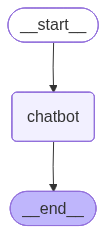

In [100]:
# Step 5: Compile the Graph
from IPython.display import Image, display
# IPython.display: Jupyter Notebook 셀에 이미지/HTML 등 리치 콘텐츠를 출력하기 위한 모듈
# Image: 이미지 바이트 데이터를 Jupyter가 렌더링 가능한 형태로 감싸는 클래스
# display: 객체를 셀 출력창에 실제로 표시하는 함수

graph = graph_builder.compile()
# 지금까지 graph_builder에 등록한 내용들을 모두 모아서 실행 가능한 그래프로 변환
# - State 정의 (messages 필드 + add_messages 리듀서)
# - chatbot 노드 (LLM 호출 로직)
# - START -> chatbot -> END 엣지(연결) 구조
#
# compile() 시점에 LangGraph는 다음을 검증/준비함:
# - 모든 노드가 그래프 상에서 도달 가능한지 (고립된 노드가 없는지)
# - START에서 END까지 경로가 존재하는지
# - state 스키마와 각 노드의 입출력이 호환되는지
#
# compile()이 끝나면 graph는 .invoke(), .stream() 등을 호출해서
# 실제로 실행할 수 있는 "실행 가능한 객체"가 됨
# (그 전까지의 graph_builder는 그냥 설계도일 뿐, 직접 실행할 수는 없음)

display(Image(graph.get_graph().draw_mermaid_png()))
# graph.get_graph(): 컴파일된 그래프에서 노드/엣지 구조 정보를 추출
# .draw_mermaid_png(): 추출한 구조를 Mermaid 다이어그램 문법으로 변환 후 PNG 이미지로 렌더링
#                       (내부적으로 외부 렌더링 서비스를 호출하므로 인터넷 연결 필요)
# Image(...): PNG 바이트 데이터를 IPython이 표시 가능한 이미지 객체로 변환
# display(...): 변환된 이미지를 Jupyter Notebook 셀 출력 영역에 실제로 그려서 보여줌
#
# 결과적으로: START -> chatbot -> END 형태의 단순한 흐름이
# 박스와 화살표로 이루어진 다이어그램 이미지로 출력됨

In [102]:
question = "넌 어떤 기능이 있어"
result = graph.invoke({"messages": question})
print("입력:", {"messages": question})
print("출력:", result)
print(f"최종 메시지: {result['messages'][1].content }")


입력: {'messages': '넌 어떤 기능이 있어'}
출력: {'messages': [HumanMessage(content='넌 어떤 기능이 있어', additional_kwargs={}, response_metadata={}, id='801777b7-6a76-4983-9f73-8223dca0192a'), AIMessage(content='좋아요 — 간단히 정리해볼게요. 나는 다음 같은 일을 도와줄 수 있어요.\n\n- 정보 제공·설명: 역사, 과학, 기술, 문화 등 다양한 주제에 대해 배경 지식이나 개념 설명(단, 지식은 2024년 6월 기준).\n- 질문 답변·문제 해결: 일반 질문에 대한 답변, 논리적 추론, 단계별 문제 풀이.\n- 글쓰기·편집: 이메일, 보고서, 자기소개서, 기사, 블로그, 요약, 문장 교정·스타일 개선 등.\n- 번역·현지화: 여러 언어 간 번역(한국어 포함) 및 자연스러운 표현 바꾸기.\n- 코딩 지원: 코드 작성·수정·디버깅, 알고리즘 설명, 예제 및 테스트 케이스 제공(코드 직접 실행은 불가).\n- 학습·튜터링: 개념 설명, 연습문제 제작, 공부 계획 세우기.\n- 아이디어·기획: 브레인스토밍, 마케팅/프로젝트/일정 기획, 체크리스트 작성.\n- 창작 활동: 시·소설·시나리오·캐릭터·대화문 등 창작물 생성.\n- 요약·정리: 긴 글의 핵심 요점 요약, 비교표 작성, 장단점 정리.\n- 데이터·스프레드시트 도움: 엑셀/구글시트 함수 설명, 데이터 정리 방법 제안(복잡한 통계 분석은 한계).\n- 권고·가이드: 일반적인 생활·건강·금융 팁 제공(전문가의 개인 맞춤형 진단·법적·의료·재무 자문은 대체 불가).\n\n제약(중요):\n- 실시간 웹 검색이나 최신 사건 확인은 불가(응답은 2024-06 기준 지식에 기반).\n- 실제 행동(결제·서류 제출 등)을 대신 수행할 수 없음.\n- 민감한 개인정보는 공유하지 마세요. 잘못된 정보(허위)나 실수 가능성이 있으니 중요한 결정 전엔 전문가나 원문 자료로 확인하세요.\n- 플랫폼에 

In [103]:
import gradio as gr
# gradio: 머신러닝/AI 모델을 위한 웹 UI를 몇 줄의 코드로 만들어주는 라이브러리
# gr.ChatInterface는 챗봇 형태의 웹 UI를 빠르게 만들어주는 전용 컴포넌트


def chat(user_input: str, history):
    # Gradio의 ChatInterface가 매번 사용자 입력이 들어올 때마다 자동으로 호출하는 콜백 함수
    # user_input: 사용자가 입력창에 친 메시지 (문자열)
    # history: 지금까지의 대화 기록 (Gradio가 자체적으로 관리하는 UI용 히스토리)
    #          -> 단, 이 함수 안에서는 history를 사용하지 않고 있음
    #             (즉, LangGraph 쪽 대화 기억은 Gradio의 history와는 별개로 동작 중)

    initial_state = State(messages=[{"role": "user", "content": user_input}])
    # 매번 새로운 State 인스턴스를 생성
    # messages 필드에는 "지금 사용자가 입력한 메시지 1개"만 담음
    # {"role": "user", "content": user_input} 형태의 dict는
    # LangChain/LangGraph가 내부적으로 자동으로 HumanMessage 객체로 변환해서 처리해줌

    result = graph.invoke(initial_state)
    # 컴파일된 그래프를 실행
    # 그래프 흐름: START -> chatbot 노드(LLM 호출) -> END
    # chatbot 노드 안에서 llm.invoke(old_state.messages)를 호출하므로,
    # 여기서는 "사용자 메시지 1개"만 담긴 messages가 LLM에 전달됨
    #
    # ⚠️ 주의할 점: initial_state.messages에는 매번 "이번 입력 1개"만 들어있고,
    #            "이전 대화 기록"은 전혀 포함되어 있지 않음
    #            즉, 매 호출마다 그래프를 새로 시작하는 것이므로
    #            이 챗봇은 사실상 "대화 맥락(이전 turn)을 기억하지 못하는" 상태임
    #            (add_messages 리듀서는 "같은 그래프 실행 안에서" 메시지를 누적해주는 것이고,
    #             매번 새로 invoke()를 호출하면 그 전 실행 결과와는 연결되지 않음)

    print(result)
    # 디버깅용 출력: 그래프 실행 결과(전체 State, 즉 messages 리스트)를 터미널/콘솔에 출력
    # 보통 개발 중에 내부 동작을 확인하기 위한 용도이며, 실제 서비스에서는 제거하는 게 일반적

    return result['messages'][-1].content
    # result['messages']에는 [HumanMessage(질문), AIMessage(응답)] 형태로 들어있음
    # (chatbot 노드가 반환한 새 messages가 add_messages에 의해 기존 것에 추가되었기 때문)
    # [-1]로 리스트의 마지막 항목(=AI의 응답 메시지)을 꺼내고
    # .content로 그 메시지의 실제 텍스트만 추출해서 반환
    # 이 반환값이 Gradio UI의 채팅창에 챗봇의 답변으로 표시됨


gr.ChatInterface(chat, type="messages").launch()
# gr.ChatInterface(...): chat 함수를 연결한 채팅 UI 컴포넌트를 생성
# type="messages": 대화 내용을 OpenAI 스타일의 {"role": ..., "content": ...} 메시지 형식으로 다룸
# .launch(): 로컬 웹 서버를 띄워서 실제로 브라우저에서 접속 가능한 채팅 화면을 실행함
# (기본적으로 http://127.0.0.1:7860 같은 주소로 열림)

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


# [EX3]  다중 필드  State와 LLM 요약 노드를 결합

In [104]:
## 그래프에 LLM 포함시키기
# ✅ 포인트: 이번엔 다중 필드를 가진 State와 LLM 요약 노드를 결합해봅니다.


# ✅ 포인트: 요청 제한자 — LLM 호출 빈도 제어(과금/한도 초과 방지용).
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_openai import ChatOpenAI

# ✅ 포인트: 분당 10회 제한을 초당 단위로 환산(0.167 rps)해 스로틀링 구성.
throttle = InMemoryRateLimiter(
    requests_per_second=0.167,     # rps 설정(= 10 req/min)
    check_every_n_seconds=0.1,     # 주기적으로 토큰 버킷 체크
    max_bucket_size=10,            # 버킷 용량(버스트 허용치)
)

# ✅ 포인트: LLM 인스턴스 생성 — 위 스로틀러를 적용해 안전하게 호출합니다.
llm = ChatOpenAI(
    model="gpt-5-mini",  # 경량·저지연 목적의 모델 선택(실습에 적합)
    rate_limiter=throttle          # 과도 호출 방지
)

# ✅ 포인트: 세 가지 필드를 가진 State — 입력(티켓 수)→계산(우선순위)→요약(LLM).
class TicketCalc(TypedDict):
    tickets_count: int      # 처리할 티켓 개수(입력)
    priority_tier: int      # 우선순위: sqrt 기반 정수(많을수록 상위 티어)
    briefing: str           # LLM이 생성한 간단 요약 결과

In [105]:
# ✅ 포인트: 프롬프트/파서 — 체인 구성에 필요한 기본 컴포넌트입니다.
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# ✅ 포인트: 우선순위 계산 — 티켓 수의 제곱근을 정수화(간단·직관적 중요도 지표).
def compute_tier(rec):
    return {"priority_tier": int(rec["tickets_count"] ** 0.5)}  # 예: 16개→sqrt=4→4

# ✅ 포인트: 요약 생성 — 우선순위(숫자)를 문장 수로 사용해 말머리표 요약을 생성합니다.
def draft_briefing(rec):
    prompt = ChatPromptTemplate([
        ('system', '고객지원 문서 요약을 명확히 작성하세요.'),  # 시스템 지시: 톤/역할 지정
        ('user', '{length} 문장으로 고객지원 워크플로를 말머리표 형태로 요약하세요.')  # 사용자 지시
    ])
    summary_chain = prompt | llm | StrOutputParser()  # 포인트: 프롬프트→LLM→문자열 파싱 체인
    return {"briefing": summary_chain.invoke({'length': rec['priority_tier']})}  # 길이=티어

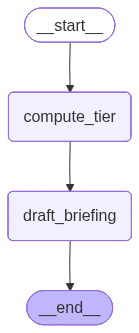

In [106]:
# ✅ 포인트: 그래프 구성 — 계산 후 요약을 수행하는 직선형 파이프라인.
flow = StateGraph(TicketCalc)
flow.add_node("compute_tier", compute_tier)       # 1단계: 우선순위 계산
flow.add_node("draft_briefing", draft_briefing)   # 2단계: LLM 요약

# ✅ 포인트: 실행 경로 — START→compute_tier→draft_briefing→END.
flow.add_edge(START, "compute_tier")
flow.add_edge("compute_tier", "draft_briefing")
flow.add_edge("draft_briefing", END)

# ✅ 포인트: 컴파일 — 실행 가능한 그래프 객체로 변환.
support_notes = flow.compile()
support_notes  # 구조 미리보기

In [107]:

# ✅ 포인트: 실행 — 티켓 16개를 입력으로 넣어 티어=4, 4문장 요약을 기대합니다.
seed = {'tickets_count': 16}  # 예시 입력(직관적 정수)
out = support_notes.invoke(seed)  # 그래프 실행
out  # 계산된 priority_tier와 briefing 확인

{'tickets_count': 16,
 'priority_tier': 4,
 'briefing': '- 고객 문의는 이메일·채팅·전화·SNS 등 다양한 채널로 접수되어 티켓 시스템에 기록됩니다.  \n- 지원 요청은 문제 유형·심각도·고객 등급을 기준으로 분류·우선순위화되어 적절한 팀과 담당자에게 라우팅됩니다.  \n- 에이전트는 표준 절차와 지식을 활용해 문제를 해결하고, 필요 시 기술·제품팀으로 에스컬레이션하며 진행 상황을 고객에게 주기적으로 안내합니다.  \n- 문제가 해결되면 티켓을 종료하고 고객 만족도 조사를 시행하며 사례를 문서화해 재발 방지 및 서비스 개선에 반영합니다.'}